In [21]:
import numpy as np
import matplotlib.pyplot as plt


def f(x):
    return x**4 - 12 * x**3 + 30 * x**2 + 12


def df(x):
    return 4 * x**3 - 36 * x**2 + 60 * x


def horner(coef, x0):
    d = coef[-1]
    for c in reversed(coef[:-1]):
        d = d * x0 + c
    return d

In [23]:
a = float(input("a = "))
b = float(input("b = "))
if a >= b:
    raise ValueError("Trebuie sa avem a < b")

n = int(input("n = "))
m = int(input("m (<6) = "))
if m >= 6:
    raise ValueError("m trebuie sa fie < 6")
if m > n:
    raise ValueError("Gradul polinomului m nu poate fi mai mare decat n")

x_bar = float(input("x_bar = "))
if not (a <= x_bar <= b):
    raise ValueError("x_bar trebuie sa fie in intervalul [a, b]")

# Generare noduri distincte in [a, b]
while True:
    x_random = np.random.uniform(a + 1e-10, b - 1e-10, n - 1)
    x = np.sort(np.concatenate(([a], x_random, [b])))
    if np.all(np.diff(x) > 1e-10):
        break

y = f(x)

if any(abs(x_bar - xi) < 1e-10 for xi in x):
    raise ValueError("x_bar nu trebuie sa coincida cu un nod xi")

In [24]:

B = np.zeros((m + 1, m + 1))
F = np.zeros(m + 1)
for i in range(m + 1):
    for j in range(m + 1):
        B[i, j] = np.sum(x ** (i + j))
    F[i] = np.sum(y * x ** i)

coef = np.linalg.solve(B, F)

Pm_xbar = horner(coef, x_bar)
err1 = abs(Pm_xbar - f(x_bar))
err2 = np.sum(np.abs([horner(coef, xi) - yi for xi, yi in zip(x, y)]))

In [25]:

da = df(a)
db = df(b)
h = np.diff(x)  # h[i] = x[i+1] - x[i]

# Sistem HA = F (dimensiune n+1)
H = np.zeros((n + 1, n + 1))
F_s = np.zeros(n + 1)

# Prima ecuatie: 2*h0*A0 + h0*A1 = 6*((y1-y0)/h0 - da)
H[0, 0] = 2 * h[0]
H[0, 1] = h[0]
F_s[0] = 6 * ((y[1] - y[0]) / h[0] - da)

# Ecuatii interioare i=1,...,n-1
for i in range(1, n):
    H[i, i - 1] = h[i - 1]
    H[i, i] = 2 * (h[i - 1] + h[i])
    H[i, i + 1] = h[i]
    F_s[i] = 6 * ((y[i + 1] - y[i]) / h[i] - (y[i] - y[i - 1]) / h[i - 1])

# Ultima ecuatie: h_{n-1}*A_{n-1} + 2*h_{n-1}*A_n = 6*(db - (yn-yn-1)/h_{n-1})
H[n, n - 1] = h[-1]
H[n, n] = 2 * h[-1]
F_s[n] = 6 * (db - (y[-1] - y[-2]) / h[-1])

A = np.linalg.solve(H, F_s)


# bi = (yi+1 - yi)/hi - hi*(A[i+1] - A[i])/6
# ci = (x[i+1]*yi - x[i]*yi+1)/hi - hi*(x[i+1]*A[i] - x[i]*A[i+1])/6
b_s = np.zeros(n)
c_s = np.zeros(n)
for i in range(n):
    b_s[i] = (y[i + 1] - y[i]) / h[i] - h[i] * (A[i + 1] - A[i]) / 6
    c_s[i] = (x[i + 1] * y[i] - x[i] * y[i + 1]) / h[i] - h[i] * (
        x[i + 1] * A[i] - x[i] * A[i + 1]
    ) / 6


def spline_eval(x_val):
    # Sf(x) = (x-xi)^3 * A[i+1]/(6hi) + (xi+1-x)^3 * A[i]/(6hi) + bi*x + ci
    i = int(np.searchsorted(x, x_val)) - 1
    i = max(0, min(i, n - 2))
    hi = h[i]
    return (
        (x_val - x[i]) ** 3 * A[i + 1] / (6 * hi)
        + (x[i + 1] - x_val) ** 3 * A[i] / (6 * hi)
        + b_s[i] * x_val
        + c_s[i]
    )  # bi*x + ci


Sf_xbar = spline_eval(x_bar)
err_spline = abs(Sf_xbar - f(x_bar))


--- Metoda celor mai mici patrate ---
Pm(x̄) = -113.00000000018741
|Pm(x̄) - f(x̄)| = 1.8741275198408403e-10
Σ|Pm(xi) - yi| = 5.765414812231029e-10

--- Spline cubice ---
Sf(x̄) = -113.55653582635898
|Sf(x̄) - f(x̄)| = 0.5565358263589815


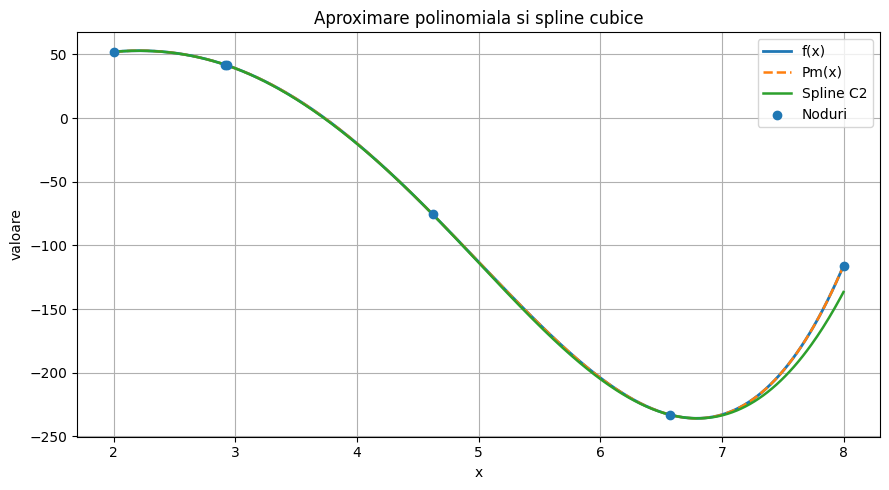

In [27]:

print("\n--- Metoda celor mai mici patrate ---")
print("Pm(x̄) =", Pm_xbar)
print("|Pm(x̄) - f(x̄)| =", err1)
print("Σ|Pm(xi) - yi| =", err2)

print("\n--- Spline cubice ---")
print("Sf(x̄) =", Sf_xbar)
print("|Sf(x̄) - f(x̄)| =", err_spline)


xx = np.linspace(a, b, 500)
ff = f(xx)
Pm_vals = [horner(coef, xi) for xi in xx]
Sf_vals = [spline_eval(xi) for xi in xx]

plt.figure(figsize=(9, 5))
plt.plot(xx, ff, label="f(x)", linewidth=2)
plt.plot(xx, Pm_vals, "--", label="Pm(x)", linewidth=1.8)
plt.plot(xx, Sf_vals, label="Spline C2", linewidth=1.8)
plt.scatter(x, y, zorder=5, label="Noduri")
plt.legend()
plt.title("Aproximare polinomiala si spline cubice")
plt.xlabel("x")
plt.ylabel("valoare")
plt.grid(True)
plt.tight_layout()
plt.show()